# RUL prediction with XGBoost (OOP version)

| Pillar | Where it appears in this notebook |
|---|---|
| **Abstraction** | `BaseRULModel` / `BaseRULPreprocessor` (in `src/base.py`) define *what* must be done; callers use `fit()`, `predict()`, `prepare()` without knowing *how*. |
| **Encapsulation** | Private state (`_model`, `_rul_cap`, `_random_state`) exposed only via properties with validation. |
| **Inheritance** | `TabularPreprocessor` extends `BaseRULPreprocessor`; `XGBRULModel` extends `BaseRULModel`. |
| **Polymorphism** | `XGBRULModel` overrides `_build_model`, `_fit_model`, `_predict_raw`, `_postprocess`, `save`; `ExperimentRunner` drives it through the base-class interface. |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBRegressor

from src.handle_data import CMAPSSDataLoader
from src.base import BaseRULModel, BaseRULPreprocessor, ExperimentRunner

## 1. Load data

In [2]:
loader = CMAPSSDataLoader(subset="FD001")
train_df, test_df, test_last = loader.load()

In [3]:
train_df.head()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


In [4]:
test_last.head()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21,RUL
0,1,31,-0.0006,0.0004,100.0,518.67,642.58,1581.22,1398.91,14.62,...,2388.06,8130.11,8.4024,0.03,393,2388,100.0,38.81,23.3552,112
1,2,49,0.0018,-0.0001,100.0,518.67,642.55,1586.59,1410.83,14.62,...,2388.09,8126.90,8.4505,0.03,391,2388,100.0,38.81,23.2618,98
2,3,126,-0.0016,0.0004,100.0,518.67,642.88,1589.75,1418.89,14.62,...,2388.14,8131.46,8.4119,0.03,395,2388,100.0,38.93,23.2740,69
3,4,106,0.0012,0.0004,100.0,518.67,642.78,1594.53,1406.88,14.62,...,2388.11,8133.64,8.4634,0.03,395,2388,100.0,38.58,23.2581,82
4,5,98,-0.0013,-0.0004,100.0,518.67,642.27,1589.94,1419.36,14.62,...,2388.15,8125.74,8.4362,0.03,394,2388,100.0,38.75,23.4117,91


In [5]:
test_df.head()

,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,0.0023,0.0003,100.0,518.67,643.02,1585.29,1398.21,14.62,...,521.72,2388.03,8125.55,8.4052,0.03,392,2388,100.0,38.86,23.3735
1,1,2,-0.0027,-0.0003,100.0,518.67,641.71,1588.45,1395.42,14.62,...,522.16,2388.06,8139.62,8.3803,0.03,393,2388,100.0,39.02,23.3916
2,1,3,0.0003,0.0001,100.0,518.67,642.46,1586.94,1401.34,14.62,...,521.97,2388.03,8130.10,8.4441,0.03,393,2388,100.0,39.08,23.4166
3,1,4,0.0042,0.0000,100.0,518.67,642.44,1584.12,1406.42,14.62,...,521.38,2388.05,8132.90,8.3917,0.03,391,2388,100.0,39.00,23.3737
4,1,5,0.0014,0.0000,100.0,518.67,642.51,1587.19,1401.92,14.62,...,522.15,2388.03,8129.54,8.4031,0.03,390,2388,100.0,38.99,23.4130


In [6]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 27 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   engine_id  20631 non-null  int64  
 1   cycle      20631 non-null  int64  
 2   setting_1  20631 non-null  float64
 3   setting_2  20631 non-null  float64
 4   setting_3  20631 non-null  float64
 5   sensor_1   20631 non-null  float64
 6   sensor_2   20631 non-null  float64
 7   sensor_3   20631 non-null  float64
 8   sensor_4   20631 non-null  float64
 9   sensor_5   20631 non-null  float64
 10  sensor_6   20631 non-null  float64
 11  sensor_7   20631 non-null  float64
 12  sensor_8   20631 non-null  float64
 13  sensor_9   20631 non-null  float64
 14  sensor_10  20631 non-null  float64
 15  sensor_11  20631 non-null  float64
 16  sensor_12  20631 non-null  float64
 17  sensor_13  20631 non-null  float64
 18  sensor_14  20631 non-null  float64
 19  sensor_15  20631 non-null  float64
 20  sensor_16  20631 

In [7]:
print('Constant columns:', BaseRULPreprocessor.find_constant_columns(train_df))

Constant columns: ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


## 2. Concrete preprocessor (inherits cleaning logic from the base class)

In [8]:
class TabularPreprocessor(BaseRULPreprocessor):
    """Flat rows + rolling-window features, for tree models such as XGBoost."""

    def __init__(self, rul_cap=125, window=27):
        super().__init__(rul_cap=rul_cap, window=window, clip_test_target=True)

    def _add_rolling_features(self, df):
        df = df.sort_values(["engine_id", "cycle"]).copy()
        grouped = df.groupby("engine_id", sort=False)
        for col in self.SENSOR_COLS:
            df[f"{col}_roll_mean"] = grouped[col].transform(
                lambda s: s.rolling(window=self.window, min_periods=1).mean())
            df[f"{col}_roll_std"] = grouped[col].transform(
                lambda s: s.rolling(window=self.window, min_periods=2).std())
        return df

    def prepare(self, train_df, test_df, test_last):        # overrides the abstract method
        train_df, test_df = self._clean(train_df, test_df)
        train_df = self._add_rolling_features(train_df).drop(columns=["engine_id"])
        test_df = self._add_rolling_features(test_df)

        X_train = train_df.drop(columns=["RUL"])
        y_train = train_df["RUL"]
        # one row per test engine: its last recorded cycle
        X_test = test_df.groupby("engine_id").tail(1).drop(columns=["engine_id"])
        y_test = self._test_target(test_last)
        return X_train, y_train, X_test, y_test

## 3. Concrete model (inherits fit / predict / evaluate from the base class)

In [9]:
class XGBRULModel(BaseRULModel):
    """XGBoost regressor; predictions are clipped to the valid RUL range."""

    def __init__(self, rul_cap=125, random_state=42):
        super().__init__(name="XGBoost", rul_cap=rul_cap)
        self._random_state = random_state

    def _build_model(self, X):
        return XGBRegressor(random_state=self._random_state)

    def _fit_model(self, X, y, **kwargs):
        self._model.fit(X, y)

    def _predict_raw(self, X):
        return self._model.predict(X)

    def _postprocess(self, predictions):                    # polymorphic hook
        return np.clip(predictions, 0, self.rul_cap)

    def save(self, path="xgb_model.json"):
        self._model.save_model(path)

## 4. Run the experiment through the abstract interface

In [10]:
runner = ExperimentRunner(TabularPreprocessor(rul_cap=125, window=27),
                          XGBRULModel(rul_cap=125, random_state=42))
print(runner)
print(runner.run(train_df, test_df, test_last).round(4))

ExperimentRunner(TabularPreprocessor(rul_cap=125, window=27), XGBRULModel(name='XGBoost', not fitted))
              MAE       MSE     RMSE      R2
Training   2.2909   11.9345   3.4546  0.9931
Testing   11.5569  266.8502  16.3356  0.8338


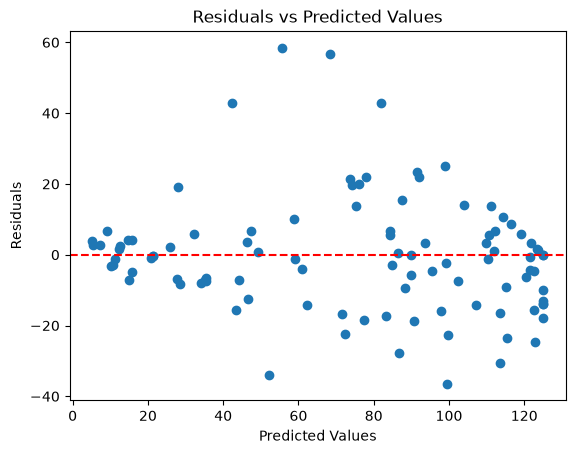

In [11]:
class ResidualPlotter:
    """Residuals-vs-predicted scatter plot."""

    @staticmethod
    def plot(y_true, y_pred):
        residual = np.asarray(y_true) - np.asarray(y_pred)
        plt.scatter(y_pred, residual)
        plt.axhline(y=0, color="red", linestyle="--")
        plt.xlabel("Predicted Values")
        plt.ylabel("Residuals")
        plt.title("Residuals vs Predicted Values")
        plt.show()

d = runner.data
ResidualPlotter.plot(d["y_test"], d["y_test_pred"])